# Challenge — Red neuronal con Keras 3
### Universidad EAFIT | SI3003 — Introducción a la Inteligencia Artificial

---

## Objetivo

En clase construimos una red neuronal para clasificación de imágenes usando **Keras 3**.

En este ejercicio aplicarás **la misma receta** sobre un dataset diferente: **CIFAR-10 convertido a escala de grises**.

No necesitas diseñar un pipeline nuevo. La descarga, conversión a escala de grises y visualización están resueltas. Tu trabajo es completar únicamente las etapas de Keras que vimos en clase:

```text
Datos → Normalización → Modelo → Loss + Optimizer → fit() → evaluate() → Predicción
```

Las celdas marcadas con `# TODO` son las que debes completar.


---
## 0. Librerías


In [1]:
import keras
from keras import layers
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
keras.utils.set_random_seed(SEED)

print(f"Keras version : {keras.__version__}")
print(f"Backend       : {keras.backend.backend()}")


Keras version : 3.15.1
Backend       : tensorflow


---
# 1. Dataset: CIFAR-10

CIFAR-10 contiene 50,000 imágenes de entrenamiento y 10,000 de prueba. Las imágenes originales son de **32×32×3** y pertenecen a 10 categorías:

`airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck`.


In [2]:
# Esta parte está resuelta.
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

y_train = y_train.squeeze()
y_test = y_test.squeeze()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("X_train original:", X_train.shape)
print("X_test original :", X_test.shape)
print("y_train         :", y_train.shape)


X_train original: (50000, 32, 32, 3)
X_test original : (10000, 32, 32, 3)
y_train         : (50000,)


## 1.1 RGB → escala de grises

Usaremos la transformación:

$$Gray = 0.299R + 0.587G + 0.114B$$

Esta parte está resuelta porque el objetivo del ejercicio es practicar Keras.


In [3]:
X_train = (
    0.299 * X_train[..., 0] +
    0.587 * X_train[..., 1] +
    0.114 * X_train[..., 2]
)

X_test = (
    0.299 * X_test[..., 0] +
    0.587 * X_test[..., 1] +
    0.114 * X_test[..., 2]
)

print("X_train grayscale:", X_train.shape)
print("X_test grayscale :", X_test.shape)


X_train grayscale: (50000, 32, 32)
X_test grayscale : (10000, 32, 32)


### Pregunta 1

Después de convertir las imágenes a escala de grises, cada imagen tiene tamaño `32×32`.

¿Cuántos valores tendrá cada imagen después de aplicar `Flatten()`?

**Respuesta:** $32 \times 32 = 1\,024$ valores. Al pasar a escala de grises desaparece el eje de canales; con RGB habrían sido $32\times32\times3 = 3\,072$.


## 1.2 Normalización

Los valores de los píxeles están entre 0 y 255. Completa el código para llevarlos al rango `[0,1]`.


In [4]:
# TODO 1 — Normalización
X_train = X_train.astype("float32") / 255.0
X_test  = X_test.astype("float32") / 255.0

print(X_train.min(), X_train.max())


0.0 1.0


In [5]:
# Validación TODO 1
assert X_train.dtype == np.float32
assert X_test.dtype == np.float32
assert X_train.min() >= 0.0
assert X_train.max() <= 1.0
print("✓ Datos normalizados correctamente")


✓ Datos normalizados correctamente


## 1.3 Visualización

Esta parte está resuelta.


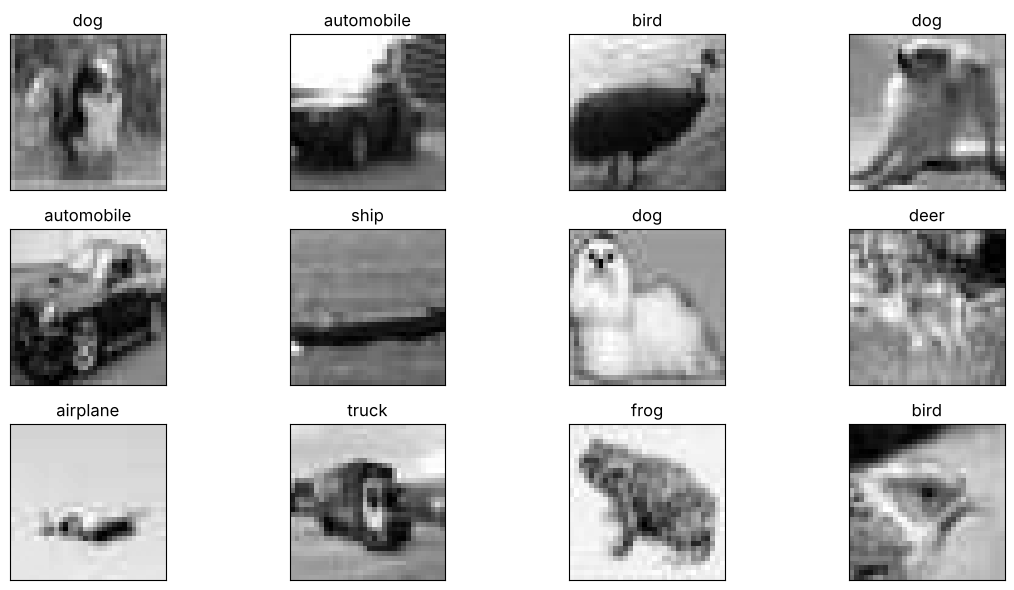

In [6]:
plt.figure(figsize=(12, 6))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()


---
# 2. Construir la red neuronal

Construiremos la misma arquitectura conceptual vista en clase:

```text
Imagen 32×32
   ↓
Flatten
   ↓
1024 valores
   ↓
Dense(128)
   ↓
ReLU
   ↓
Dense(10)
   ↓
Logits
```

> La última capa **no** debe tener Softmax. Trabajaremos con logits.


In [7]:
# TODO 2 — Completa la arquitectura
model = keras.Sequential([
    keras.Input(shape=(32, 32)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10)
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 132,490 (517.54 KB)

 Trainable params: 132,490 (517.54 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Validación TODO 2
expected_params = (1024 * 128 + 128) + (128 * 10 + 10)
assert model.count_params() == expected_params
print(f"✓ Arquitectura correcta: {model.count_params():,} parámetros")


✓ Arquitectura correcta: 132,490 parámetros


### Preguntas

**2.** ¿Por qué necesitamos `Flatten()` antes de la primera capa `Dense`?

**Respuesta:** Una capa `Dense` calcula $\mathbf{z} = W\mathbf{x} + \mathbf{b}$ y espera que cada ejemplo sea un **vector** de características, pero cada imagen llega como una matriz de $32\times32$. `Flatten()` la convierte en un vector de 1 024 valores, sin parámetros: solo reordena los píxeles. Así cada una de las 128 neuronas ocultas tiene un peso por píxel ($1024 \times 128$ pesos).

**3.** ¿Por qué la última capa tiene 10 neuronas?

**Respuesta:** Porque CIFAR-10 tiene **10 clases**. Cada neurona produce el *logit* (puntaje sin normalizar) de una clase. La clase predicha es la de mayor logit, y aplicando Softmax a los 10 logits se obtiene una distribución de probabilidad sobre las 10 categorías.

**4.** ¿Qué función cumple `ReLU`?

**Respuesta:** Introduce **no linealidad**: $g(x)=\max(0,x)$. Sin ella, `Dense(128)` seguida de `Dense(10)` equivaldría a una única transformación lineal ($W_2(W_1x+b_1)+b_2 = W'x+b'$) y la red no sería más expresiva que una regresión logística. Con ReLU, la capa oculta aprende combinaciones no lineales de los píxeles. Además es barata de calcular y no se satura para valores positivos, lo que facilita el flujo del gradiente.


---
# 3. Configurar el entrenamiento

Usaremos:

- `Adam`
- `SparseCategoricalCrossentropy`
- `accuracy`

Como la red produce logits, la pérdida debe configurarse con `from_logits=True`.


In [9]:
lr_rate = 0.001

# TODO 3 — Configura el entrenamiento
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=lr_rate),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)


### Pregunta 5

¿Por qué usamos `from_logits=True`?

**Respuesta:** Porque la última capa (`Dense(10)` sin activación) entrega **logits**, no probabilidades. Con `from_logits=True` la pérdida aplica internamente Softmax y luego la cross-entropy en una sola operación numéricamente estable (con el truco *log-sum-exp*), evitando desbordamientos de $e^{z}$ y el cálculo de $\log(0)$. Si no lo indicáramos, Keras interpretaría los logits como si ya fueran probabilidades y la pérdida y los gradientes serían incorrectos.


---
# 4. Entrenar el modelo

Usaremos 10 épocas y mini-batches de 64 ejemplos. Completa `fit()`.


In [10]:
epochs = 10
batch_size = 64

# TODO 4 — Entrenamiento
history = model.fit(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_test, y_test),
    shuffle=True,
    verbose=2
)


Epoch 1/10


782/782 - 3s - 3ms/step - accuracy: 0.2544 - loss: 2.0633 - val_accuracy: 0.2804 - val_loss: 2.0026


Epoch 2/10


782/782 - 2s - 3ms/step - accuracy: 0.3062 - loss: 1.9467 - val_accuracy: 0.3090 - val_loss: 1.9371


Epoch 3/10


...

782/782 - 2s - 3ms/step - accuracy: 0.3716 - loss: 1.7745 - val_accuracy: 0.3583 - val_loss: 1.8024


Epoch 9/10


782/782 - 2s - 3ms/step - accuracy: 0.3777 - loss: 1.7621 - val_accuracy: 0.3584 - val_loss: 1.7949


Epoch 10/10


782/782 - 2s - 3ms/step - accuracy: 0.3816 - loss: 1.7496 - val_accuracy: 0.3645 - val_loss: 1.7851


### Preguntas

**6.** ¿Qué representa una `epoch`?

**Respuesta:** Una **pasada completa por todo el conjunto de entrenamiento**: el modelo ve las 50 000 imágenes una vez. Con `epochs=10`, cada imagen se usa 10 veces para actualizar los parámetros, y al final de cada época Keras reporta las métricas de entrenamiento y validación.

**7.** ¿Qué representa `batch_size=64`?

**Respuesta:** Que los parámetros se actualizan usando **mini-batches de 64 imágenes**: se hace el *forward pass* de 64 ejemplos, se promedia su pérdida, se calculan los gradientes con backpropagation y Adam da **un paso**. Con 50 000 imágenes hay $\lceil 50000/64 \rceil = 782$ actualizaciones por época. Es un compromiso entre el gradiente exacto pero costoso de *full-batch* y el muy ruidoso de SGD con un solo ejemplo.


## 4.1 Curvas de aprendizaje

Esta parte está resuelta.


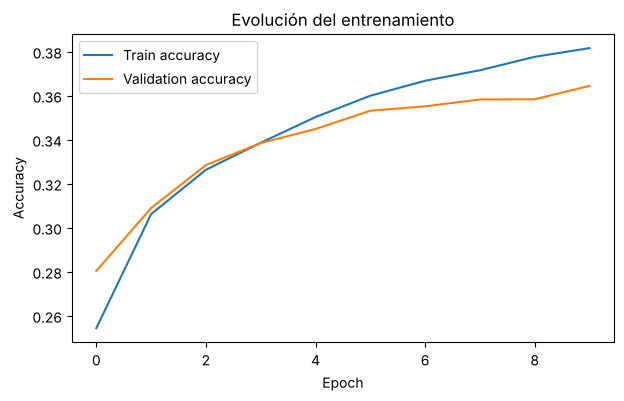

In [11]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Evolución del entrenamiento")
plt.legend()
plt.show()


### Pregunta 8

Observa las dos curvas. ¿Hay evidencia de overfitting? Justifica brevemente.

**Respuesta:** **No hay overfitting significativo** en estas 10 épocas. Ambas curvas suben juntas: la accuracy de entrenamiento pasa de ≈ 0.25 a ≈ 0.38 y la de validación de ≈ 0.28 a ≈ 0.36. La brecha final es de solo ≈ 2 puntos y la validación sigue mejorando hasta la última época, sin estancarse ni empeorar. El problema de este modelo es más bien **underfitting**: la red no tiene capacidad suficiente para capturar la información de las imágenes, así que ni siquiera en entrenamiento pasa del 38 %. La brecha empieza a abrirse lentamente en las últimas épocas; con muchas más épocas sí aparecería sobreajuste.


---
# 5. Evaluar el modelo

Completa `evaluate()`.


In [12]:
# TODO 5 — Evaluación
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    batch_size=batch_size,
    verbose=0
)

print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")
print(f"Accuracy (%)  : {test_accuracy * 100:.2f}%")


Test loss     : 1.7851
Test accuracy : 0.3645
Accuracy (%)  : 36.45%


### Pregunta 9

Compara este resultado con Fashion-MNIST, utilizado en clase.

¿CIFAR-10 en escala de grises parece más fácil o más difícil para esta red? Justifica usando el accuracy obtenido.

**Respuesta:** **Mucho más difícil.** Con la misma receta (Flatten → Dense(128) + ReLU → Dense(10), Adam, 10 épocas) en Fashion-MNIST la red de clase alcanza **≈ 87–89 %** de accuracy en prueba. Aquí obtenemos **≈ 36 %**: mejor que el azar (10 %), pero lejos de aquel resultado.

Las razones:

- En Fashion-MNIST los objetos están **centrados, sobre fondo negro uniforme y con la misma escala**. En CIFAR-10 son fotografías naturales con fondos variados, distintos puntos de vista, posiciones, tamaños e iluminación.
- Al quitar el color se pierde información útil: el azul del cielo o del mar distingue aviones y barcos, y el verde ayuda con ranas y venados.
- Una misma clase se ve muy distinta de una imagen a otra (gatos de frente, de lado, de colores diferentes), y una red fully-connected que compara píxel a píxel no es invariante a esos desplazamientos.


---
# 6. Logits y Softmax

La salida de la red son 10 logits. Para interpretarlos como probabilidades necesitamos Softmax.


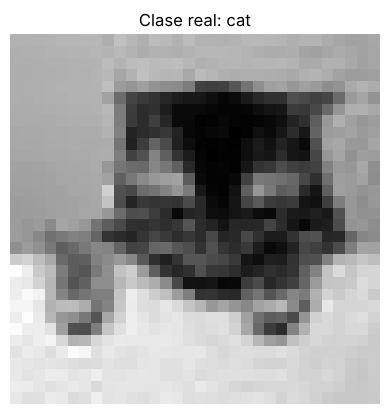

Logits:
[[-1.4124842  -0.08173217  0.27982384  1.7547925  -0.853725    0.84924453
  -0.73887813 -0.23995349 -4.8026915   0.06588092]]


In [13]:
index = 0
image = X_test[index]
true_class = y_test[index]

plt.imshow(image, cmap="gray")
plt.title(f"Clase real: {class_names[true_class]}")
plt.axis("off")
plt.show()

image_batch = np.expand_dims(image, axis=0)
logits = model(image_batch, training=False)

print("Logits:")
print(keras.ops.convert_to_numpy(logits))


In [14]:
# TODO 6 — Logits -> probabilidades
probabilities = keras.ops.softmax(logits)

# TODO 7 — Clase con mayor probabilidad
prediction = keras.ops.argmax(probabilities, axis=1)
prediction = int(keras.ops.convert_to_numpy(prediction)[0])

print("Clase real     :", class_names[true_class])
print("Clase predicha :", class_names[prediction])


Clase real     : cat
Clase predicha : cat


In [15]:
probabilities_np = keras.ops.convert_to_numpy(probabilities)[0]

print("\nProbabilidades:")
for i, p in enumerate(probabilities_np):
    marker = " ← predicción" if i == prediction else ""
    print(f"{class_names[i]:12s}: {p:.4f}{marker}")

print("\nSuma:", probabilities_np.sum())



Probabilidades:
airplane    : 0.0182
automobile  : 0.0689
bird        : 0.0989
cat         : 0.4323 ← predicción
deer        : 0.0318
dog         : 0.1748
frog        : 0.0357
horse       : 0.0588
ship        : 0.0006
truck       : 0.0799

Suma: 1.0


### Pregunta 10

¿Por qué las probabilidades producidas por `Softmax` deben sumar aproximadamente 1?

**Respuesta:** Porque Softmax normaliza por construcción:

$$
p_k = \frac{e^{z_k}}{\sum_{j=1}^{10} e^{z_j}} \;\Rightarrow\; \sum_k p_k = \frac{\sum_k e^{z_k}}{\sum_j e^{z_j}} = 1,
$$

y cada $p_k > 0$. Así los 10 valores forman una **distribución de probabilidad** sobre clases mutuamente excluyentes: cada imagen pertenece a exactamente una categoría. Decimos "aproximadamente" porque se calcula en punto flotante (`float32`) y aparecen pequeños errores de redondeo. En la salida anterior la suma es 1.0. Los logits, en cambio, pueden ser negativos y no suman nada en particular.


---
# 7. Varias predicciones

Esta parte está resuelta. Observa especialmente los errores del modelo.


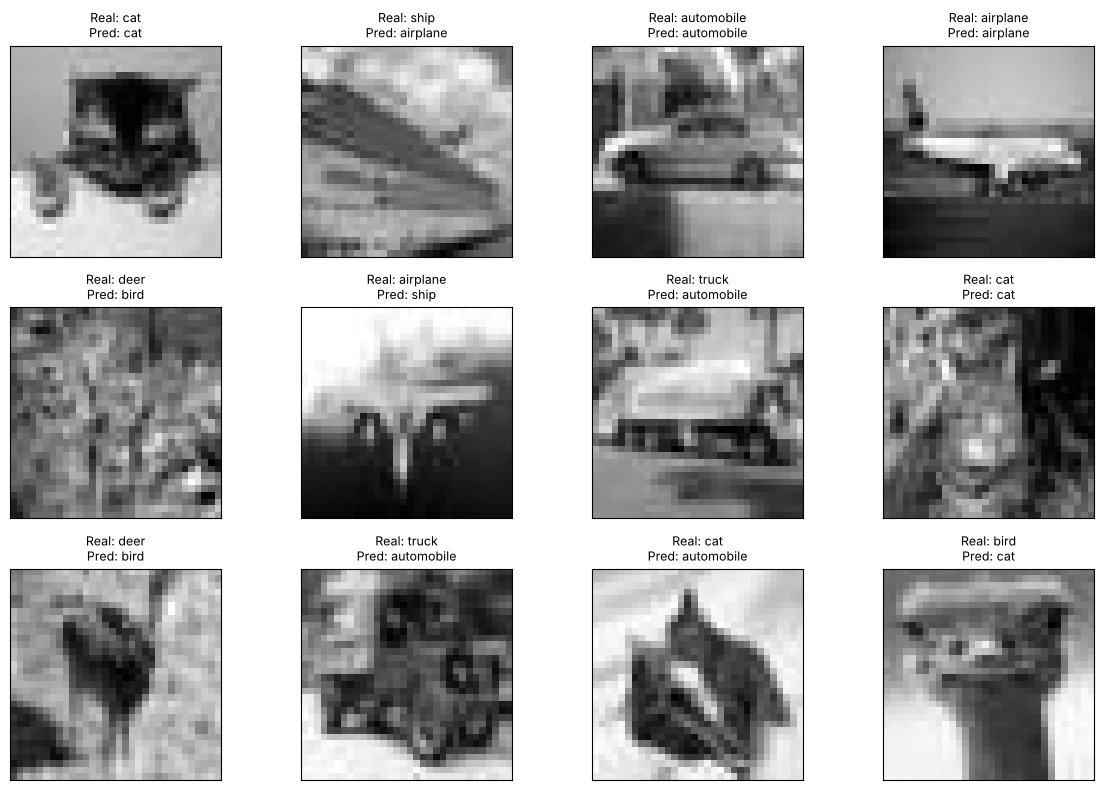

In [16]:
n = 12
logits_batch = model(X_test[:n], training=False)
predictions = keras.ops.argmax(logits_batch, axis=1)
predictions = keras.ops.convert_to_numpy(predictions)

plt.figure(figsize=(12, 8))
for i in range(n):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[i], cmap="gray")
    real = class_names[y_test[i]]
    pred = class_names[predictions[i]]
    plt.title(f"Real: {real}\nPred: {pred}", fontsize=9)
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()


Accuracy por clase:
  airplane   : 0.251
  deer       : 0.254
  horse      : 0.263
  dog        : 0.272
  cat        : 0.285
  frog       : 0.344
  bird       : 0.447
  automobile : 0.449
  truck      : 0.511
  ship       : 0.569

Confusiones más frecuentes (real -> predicha):
  deer       -> bird      : 295
  airplane   -> ship      : 229
  automobile -> truck     : 222
  dog        -> cat       : 220
  airplane   -> bird      : 204
  truck      -> automobile: 188


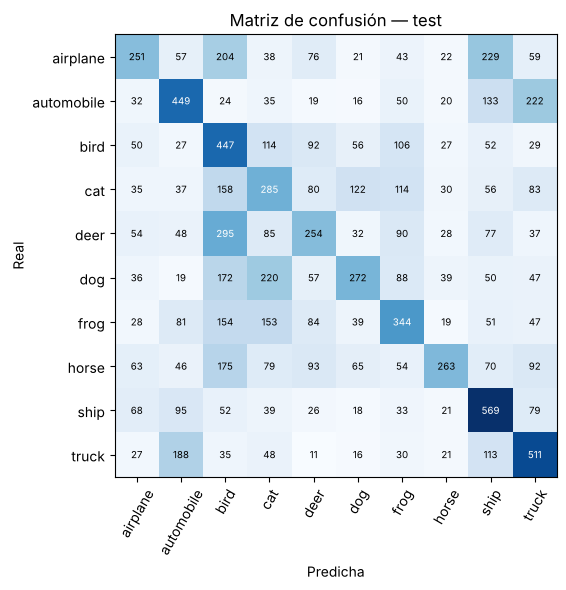

In [17]:
# Apoyo para la reflexión final: accuracy por clase y confusiones más frecuentes
all_logits = model.predict(X_test, batch_size=256, verbose=0)
y_pred_all = np.argmax(all_logits, axis=1)

cm = np.zeros((10, 10), dtype=int)
for t, p_ in zip(y_test, y_pred_all):
    cm[t, p_] += 1

print("Accuracy por clase:")
for k in np.argsort(np.diag(cm) / cm.sum(axis=1)):
    print(f"  {class_names[k]:11s}: {cm[k, k] / cm[k].sum():.3f}")

off = cm.copy(); np.fill_diagonal(off, 0)
print("\nConfusiones más frecuentes (real -> predicha):")
for idx in np.argsort(off.ravel())[::-1][:6]:
    t, p_ = divmod(idx, 10)
    print(f"  {class_names[t]:10s} -> {class_names[p_]:10s}: {off[t, p_]}")

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10), class_names, rotation=60)
ax.set_yticks(range(10), class_names)
ax.set_xlabel("Predicha"); ax.set_ylabel("Real")
ax.set_title("Matriz de confusión — test")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.show()


---
# 8. Reflexión final

### 1. ¿Cuál fue el accuracy final?

**Respuesta:** **≈ 36.5 %** en el conjunto de prueba (test loss ≈ 1.79) y ≈ 38 % en entrenamiento tras 10 épocas.

### 2. ¿Qué clases parecen más difíciles de distinguir?

**Respuesta:** Según la matriz de confusión de la celda anterior, las peores clases son **airplane (≈ 25 %), deer (≈ 25 %), horse (≈ 26 %), dog (≈ 27 %) y cat (≈ 29 %)**. Las mejores son ship (≈ 57 %) y truck (≈ 51 %). Las confusiones más frecuentes tienen sentido visual:

- **deer → bird** y **airplane → bird**: siluetas sobre fondos naturales o cielo, que en gris se parecen.
- **airplane → ship**: fondos azules y lisos (cielo o mar) que se ven igual en escala de grises.
- **automobile ↔ truck**: vehículos con formas y contextos similares.
- **dog → cat**: animales de tamaño, pose y textura parecidos.

En general, los animales se confunden entre sí y los vehículos entre sí.

### 3. Después de `Flatten()`, la imagen se convierte en un vector de 1024 valores. ¿Qué información importante sobre la imagen podría perderse al tratarla únicamente como un vector?

**Respuesta:** Se pierde la **estructura espacial**: la red ya no sabe qué píxeles son vecinos ni en qué posición relativa están. Un borde, una esquina o una textura son relaciones entre píxeles cercanos, y tras aplanar la red tendría que aprender esas relaciones desde cero para cada posición. Tampoco hay **invariancia a traslaciones**: un gato desplazado unos píxeles activa pesos completamente distintos, como si fuera otra imagen. Además, cada neurona se conecta con todos los píxeles, lo que dispara el número de parámetros sin aprovechar que los patrones locales se repiten en distintas partes de la imagen.

### 4. ¿Qué tipo de arquitectura podría aprovechar mejor la estructura espacial de las imágenes?

**Respuesta:** Las **redes neuronales convolucionales (CNN)**. Sus capas `Conv2D` aplican pequeños filtros (por ejemplo, de 3×3) que recorren toda la imagen, con lo cual:

- detectan **patrones locales** (bordes, texturas) usando la vecindad de los píxeles;
- **comparten pesos** entre posiciones, de modo que el mismo detector sirve en toda la imagen, con muchos menos parámetros e invariancia aproximada a traslaciones;
- al apilarse con *pooling* construyen una **jerarquía** que va de bordes a partes y de partes a objetos.

En CIFAR-10, incluso una CNN pequeña supera con facilidad el 60–70 %, y usar los tres canales de color ayuda aún más.

---

## Para pensar

Nuestro modelo hace:

```text
32×32 → Flatten → 1024 valores → Dense → ReLU → Dense(10)
```

Sin embargo, una imagen tiene **estructura espacial**: existen bordes, formas y patrones locales.

Este resultado nos deja preparada la siguiente pregunta del curso:

> **¿Cómo puede una red aprovechar directamente la estructura espacial de una imagen?**

La respuesta será: **Convolutional Neural Networks (CNNs)**.
